#### **STISK2133 Predictive Analytics - Assignment 1**<br>---------------------------------------------------------------------<br>PART A: REGRESSION DIAGNOSTICS & ASSUMPTION TESTING<br>---------------------------------------------------------------------

In [63]:
# -----------------------------------------
# Import Libraries
# -----------------------------------------

# Data Handling
import pandas as pd
import numpy as np


# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns


# Statistical Analysis
import scipy.stats as stats
from scipy.stats import shapiro

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


# Data Preprocessing
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA


# Machine Learning Models
from sklearn.linear_model import LinearRegression, LassoCV


# Model Selection
from sklearn.model_selection import train_test_split


# Model Evaluation
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


# Model Persistence
import pickle
from pathlib import Path

In [64]:
# ------------------------------------------------------------
# 1. Load dataset
# ------------------------------------------------------------

df = pd.read_csv("DataTrain_CoolingLoad.csv")

# Select predictors X1 to X8
feature_columns = [f"X{i}" for i in range(1, 9)]

# Select predictors and target variable
data = df[feature_columns + ["Y"]].copy()

# Handle Infinite Values
data = data.replace([np.inf, -np.inf], np.nan)

# Check Missing and Infinite Values
print("Missing and Infinite Values:")
print(data.isnull().sum())
print("Total Missing Values:", data.isnull().sum().sum())

# Remove Missing Values
data = data.dropna()

# Separate predictors and target variable
X = data[feature_columns]
y = data["Y"]

print("\nDataset shape:", X.shape)
print("Target shape:", y.shape)

Missing and Infinite Values:
X1    1
X2    5
X3    6
X4    3
X5    0
X6    1
X7    1
X8    0
Y     0
dtype: int64
Total Missing Values: 17

Dataset shape: (751, 8)
Target shape: (751,)


Part A: 1. Multicollinearity Analysis

In [65]:
# Function for calculate the VIF

def calculate_vif(data):
    X_const = add_constant(data, has_constant="add")

    vif_result = pd.DataFrame({
        "Feature": data.columns,
        "VIF": [
            variance_inflation_factor(
                X_const.values, i + 1
            )
            for i in range(data.shape[1])
        ]
    })

    return vif_result.sort_values(
        by="VIF", ascending=False
    ).reset_index(drop=True)

In [66]:
# Part A (1A): Calculate the VIF for all predictors

print("\n========== PART A(a): ORIGINAL VIF ==========")

vif_before = calculate_vif(X)

print(vif_before.to_string(
    index=False,
    float_format="%.3f"
))


========== PART A(a): ORIGINAL VIF ==========
Feature     VIF
     X2     inf
     X3     inf
     X4     inf
     X1 107.389
     X5  31.481
     X8   1.040
     X7   1.040
     X6   1.000


c:\Users\KKM\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [67]:
# Part A (1B): Identify severe multicollinearity

print("\n========== PART A(b): VIF > 10 ==========")

severe_vif = vif_before[vif_before["VIF"] > 10]

if severe_vif.empty:
    print("No predictors have VIF > 10.")
else:
    print(severe_vif.round(3).to_string(index=False, float_format="%.3f"))


========== PART A(b): VIF > 10 ==========
Feature     VIF
     X2     inf
     X3     inf
     X4     inf
     X1 107.389
     X5  31.481


Q: Explain the geometric/physical reason behind multicollinearity in this specific dataset. 

A: Based on the VIF values calculated above, Surface Area(X2), Wall Area(X3) and Roof Area(X4) have similarly high VIF values. This is because they all depend on the size of the building. When the building size increases, these features tend to change together, resulting in multicollinearity. Besides that, Relative Compactness is also strongly related to Surface Area, while Overall Height is another geometric feature of the building. However, their VIF values are lower than those of Surface Area (X2), Wall Area (X3) and Roof Area (X4), indicating that they have multicollinearity, but it is less serious.

In [68]:
# Part A (1C): LASSO FEATURE SELECTION

y = data["Y"]

# Step 1: Standardize the predictors
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Step 2: Apply Lasso Regression with Cross-Validation
lasso = LassoCV(
    cv=5,
    random_state=42,
    max_iter=100000
)

lasso.fit(X_scaled, y)

# Step 3: Display the best Alpha
print("\n========== BEST ALPHA (LAMBDA) ==========")
print("Best Alpha:", lasso.alpha_)

# Step 4: Display the coefficients
lasso_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lasso.coef_
})

print("\n========== LASSO COEFFICIENTS ==========")
print(lasso_coefficients.to_string(
    index=False,
    float_format="%.6f"
))

# Step 5: Identify selected predictors
selected_features = X.columns[
    np.abs(lasso.coef_) > 1e-8
]
if len(selected_features) == 0:
    print("No predictors were selected by Lasso.")
else:
    print("Selected Features:", selected_features.tolist())

print("\n========== SELECTED FEATURES ==========")
print(selected_features.tolist())


========== BEST ALPHA (LAMBDA) ==========
Best Alpha: 0.008536324382694504

========== LASSO COEFFICIENTS ==========
Feature  Coefficient
     X1    -5.862633
     X2    -2.180326
     X3    -0.000000
     X4    -3.347344
     X5     8.259570
     X6     0.136467
     X7     1.919873
     X8     0.033771
Selected Features: ['X1', 'X2', 'X4', 'X5', 'X6', 'X7', 'X8']

========== SELECTED FEATURES ==========
['X1', 'X2', 'X4', 'X5', 'X6', 'X7', 'X8']


In [69]:
# Step 6: Create a new dataset using selected predictors
X_selected = X[selected_features]

# Step 7: Recalculate VIF after feature selection
vif_after = calculate_vif(X_selected)

print("\n========== VIF AFTER LASSO ==========")
# Calculate VIF after removing X3
print(vif_after.to_string(
    index=False,
    float_format="%.3f"
))

# Step 8: Compare VIF before and after Lasso
print("\n========== VIF COMPARISON ==========")

vif_comparison = vif_before.merge(
    vif_after,
    on="Feature",
    how="left",
    suffixes=("_Before", "_After")
)

print(vif_comparison.to_string(
    index=False,
    float_format="%.3f"
))


========== VIF AFTER LASSO ==========
Feature     VIF
     X2 113.926
     X1 107.389
     X4  32.846
     X5  31.481
     X8   1.040
     X7   1.040
     X6   1.000

========== VIF COMPARISON ==========
Feature  VIF_Before  VIF_After
     X2         inf    113.926
     X3         inf        NaN
     X4         inf     32.846
     X1     107.389    107.389
     X5      31.481     31.481
     X8       1.040      1.040
     X7       1.040      1.040
     X6       1.000      1.000


Part A - 2. Normality Analysis

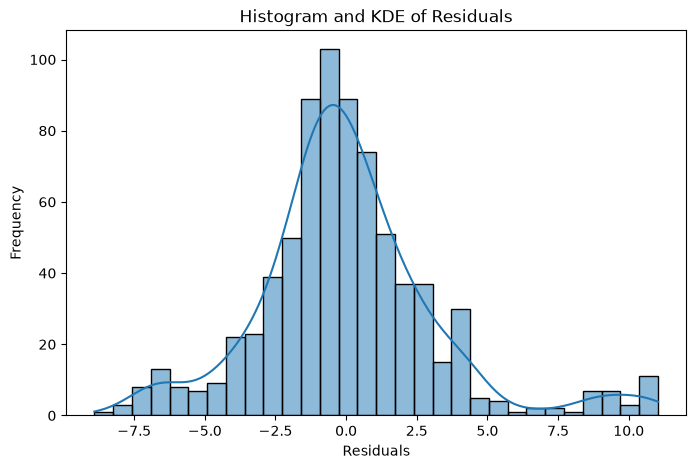

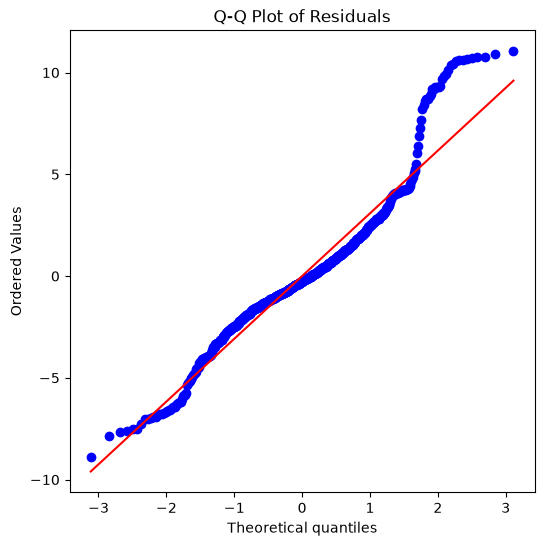

In [70]:
# Part A (2A): Plot a histogram and Q-Q Plot of the model residuals 

# Step 1: Create Linear Regression Model
model = LinearRegression()

# Step 2: Train the model using OLS regression
model.fit(X_selected, y)

# Step 3: Predict Cooling Load
y_pred = model.predict(X_selected)

# Step 4: Calculate Residuals
residuals = y - y_pred

# Plot Histogram and KDE
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True,
    bins=30
)

plt.title("Histogram and KDE of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

# Plot Q-Q Plot
plt.figure(figsize=(6, 6))

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Residuals")
plt.show()

In [71]:
# Part A (2B): Test of normality(Shapiro-Wilk Test)

# Step 1: Perform Shapiro-Wilk Test
shapiro_stat, p_value = shapiro(residuals)

# Step 2: Display the results
print("\n========== SHAPIRO-WILK TEST ==========")
print("Shapiro-Wilk Statistic:", shapiro_stat)
print("P-value:", p_value)

# Step 3: Interpret the result
if p_value > 0.05:
    print("Residuals are approximately normally distributed.")
else:
    print("Residuals are not normally distributed.")


========== SHAPIRO-WILK TEST ==========
Shapiro-Wilk Statistic: 0.9382796458903138
P-value: 4.292377545164468e-17
Residuals are not normally distributed.


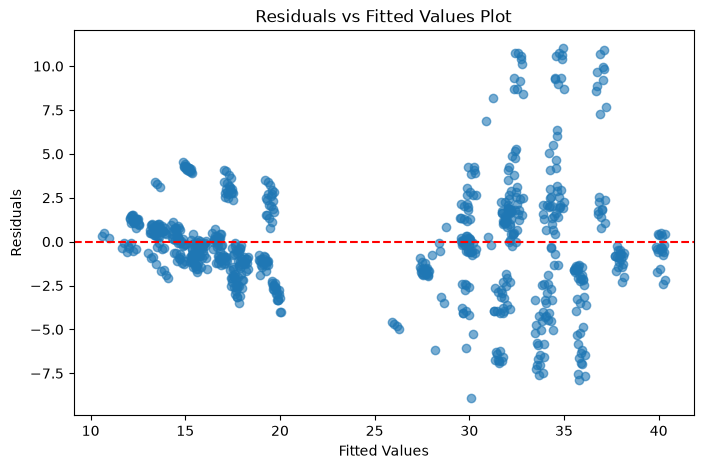

In [72]:
# Plot Residuals vs Fitted Values
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residuals vs Fitted Values Plot")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")

plt.show()

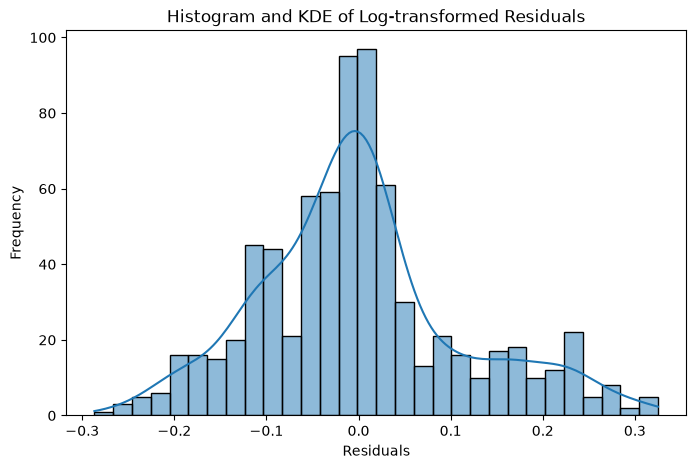

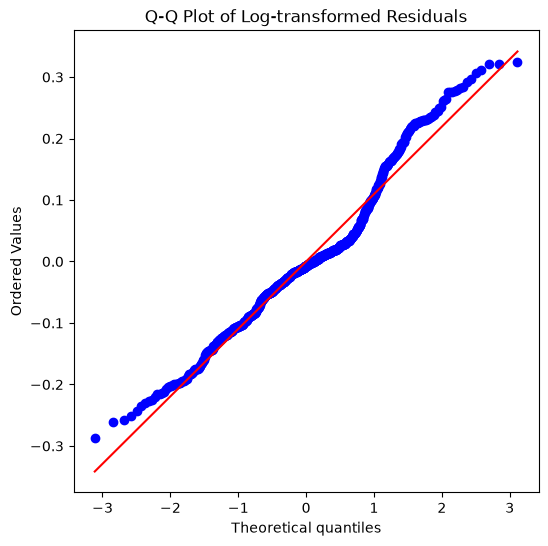


========== SHAPIRO-WILK TEST (LOG) ==========
Shapiro-Wilk Statistic: 0.9677042957225864
P-value: 8.029690238055611e-12
Residuals are not normally distributed.


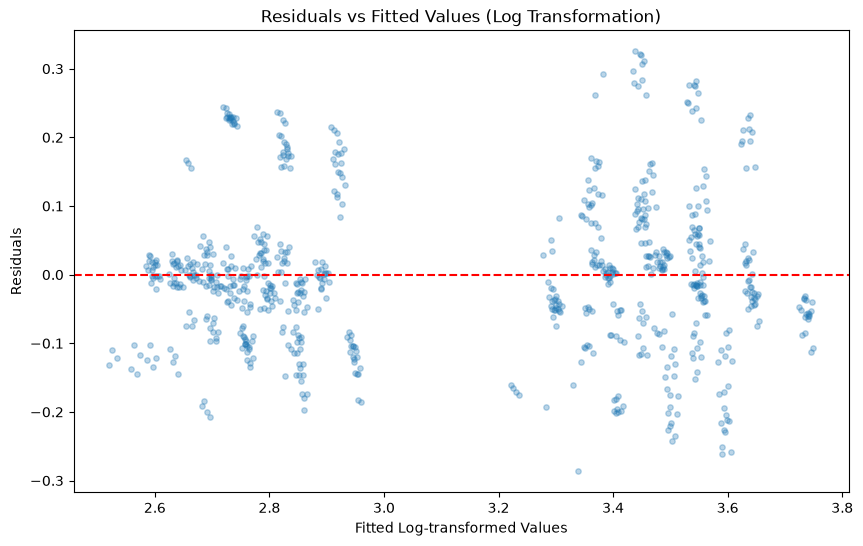

In [73]:
# Part A (2C): LOG TRANSFORMATION OF Y(Fix Heteroscedasticity)

# Step 1: Apply Log Transformation to Y
y_log = np.log(y)


# Step 2: Create Linear Regression Model
model_log = LinearRegression()


# Step 3: Train the model using Log-transformed Y
model_log.fit(X_selected, y_log)


# Step 4: Predict Log-transformed Cooling Load
y_pred_log = model_log.predict(X_selected)


# Step 5: Calculate Residuals
residuals_log = y_log - y_pred_log


# ==========================================
# NORMALITY ANALYSIS
# ==========================================

# Step 6: Plot Histogram and KDE
plt.figure(figsize=(8, 5))
sns.histplot(residuals_log, kde=True, bins=30)

plt.title("Histogram and KDE of Log-transformed Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()


# Step 7: Plot Q-Q Plot
plt.figure(figsize=(6, 6))
stats.probplot(residuals_log, dist="norm", plot=plt)

plt.title("Q-Q Plot of Log-transformed Residuals")
plt.show()


# Step 8: Perform Shapiro-Wilk Test
shapiro_stat_log, p_value_log = shapiro(residuals_log)

print("\n========== SHAPIRO-WILK TEST (LOG) ==========")
print("Shapiro-Wilk Statistic:", shapiro_stat_log)
print("P-value:", p_value_log)

if p_value_log > 0.05:
    print("Residuals are approximately normally distributed.")
else:
    print("Residuals are not normally distributed.")


# ==========================================
# HOMOSCEDASTICITY ANALYSIS
# ==========================================

# Step 9: Plot Residuals vs Fitted Values
plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred_log,
    residuals_log,
    alpha=0.3,
    s=15
)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residuals vs Fitted Values (Log Transformation)")
plt.xlabel("Fitted Log-transformed Values")
plt.ylabel("Residuals")

plt.show()


                            WLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.903
Model:                            WLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     992.7
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:19:44   Log-Likelihood:                -1844.1
No. Observations:                 751   AIC:                             3704.
Df Residuals:                     743   BIC:                             3741.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        113.5618     19.491      5.827      0.0

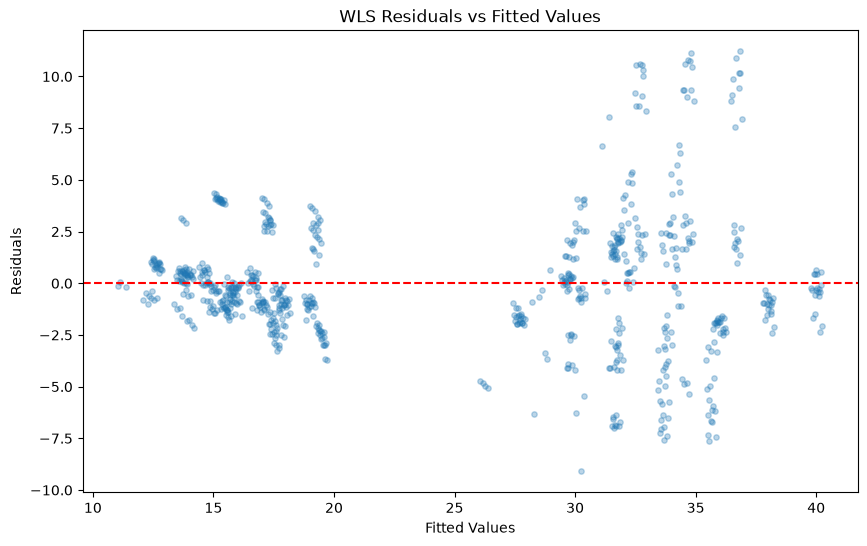

In [74]:
# Part A (2C): WEIGHTED LEAST SQUARES (WLS)(Fix Heteroscedasticity)

# Step 1: Add constant (intercept)
X_selected_const = sm.add_constant(X_selected)

# Step 2: Create and fit OLS Model
model_ols = sm.OLS(y, X_selected_const).fit()

# Step 3: Calculate squared residuals
squared_residuals = model_ols.resid ** 2

# Step 4: Estimate the error variance
variance_model = sm.OLS(
    squared_residuals,
    model_ols.fittedvalues.to_frame(name="Fitted")
).fit()

# Step 5: Calculate weights
estimated_variance = variance_model.predict(
    model_ols.fittedvalues.to_frame(name="Fitted")
)

estimated_variance = np.maximum(estimated_variance, 1e-6)

weights = 1 / estimated_variance

# Step 6: Create and fit WLS Model
model_wls = sm.WLS(
    y,
    X_selected_const,
    weights=weights
).fit()

# Step 7: Display WLS Results
print(model_wls.summary())

# Step 8: Calculate Fitted Values and Residuals
y_pred_wls = model_wls.fittedvalues
residuals_wls = model_wls.resid

# Step 9: Residuals vs Fitted Values Plot
plt.figure(figsize=(10, 6))
plt.scatter(y_pred_wls, residuals_wls, alpha=0.3, s=15)
plt.axhline(y=0, color="red", linestyle="--")
plt.title("WLS Residuals vs Fitted Values")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.show()

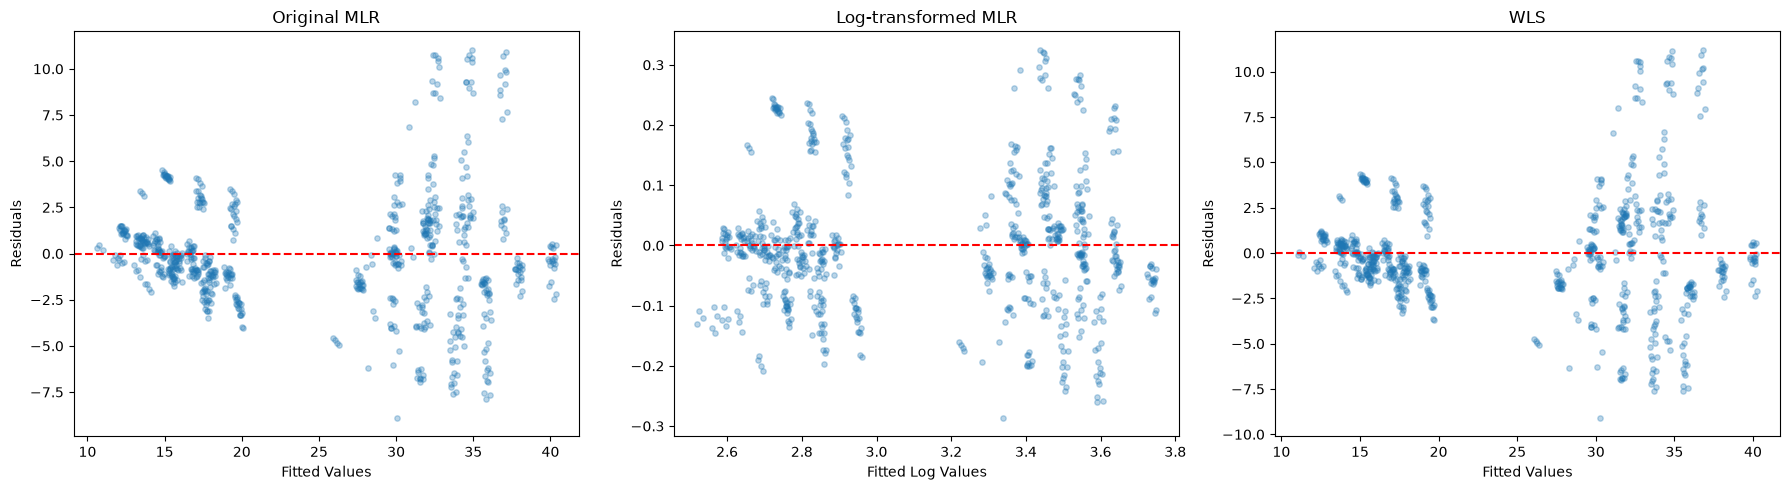

In [75]:
# Compare Original and Log-transformed

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original MLR
axes[0].scatter(y_pred, residuals, alpha=0.3, s=15)
axes[0].axhline(y=0, color="red", linestyle="--")
axes[0].set_title("Original MLR")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")

# Log-transformed MLR
axes[1].scatter(y_pred_log, residuals_log, alpha=0.3, s=15)
axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_title("Log-transformed MLR")
axes[1].set_xlabel("Fitted Log Values")
axes[1].set_ylabel("Residuals")

# WLS
axes[2].scatter(y_pred_wls, residuals_wls, alpha=0.3, s=15)
axes[2].axhline(y=0, color="red", linestyle="--")
axes[2].set_title("WLS")
axes[2].set_xlabel("Fitted Values")
axes[2].set_ylabel("Residuals")

plt.tight_layout()
plt.show()

In [76]:
# Part A (2C): HC3 robust standard errors on Log-transformed MLR Model

# Step 1: Apply Log Transformation
y_log = np.log(y)
y_log.name = "Y_log"

# Step 2: Add Constant
X_selected_const = sm.add_constant(X_selected)

# Step 3: Fit OLS using Log-transformed Y
model_log_ols = sm.OLS(y_log, X_selected_const).fit()

# Step 4: Apply HC3 Robust Standard Errors
model_log_robust = model_log_ols.get_robustcov_results(cov_type="HC3")

# Step 5: Display Results
print(model_log_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                  Y_log   R-squared:                       0.920
Model:                            OLS   Adj. R-squared:                  0.919
Method:                 Least Squares   F-statistic:                     2874.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:19:44   Log-Likelihood:                 584.89
No. Observations:                 751   AIC:                            -1154.
Df Residuals:                     743   BIC:                            -1117.
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.0784      0.609      5.054      0.0

In [77]:
# ==========================================
# HYPOTHESIS TESTING: LOG MLR WITH HC3
# ==========================================

# Step 1: Extract Robust Hypothesis Testing Results
hypothesis_results = pd.DataFrame({
    "Feature": model_log_robust.model.exog_names,
    "Coefficient": model_log_robust.params,
    "Robust SE": model_log_robust.bse,
    "t-statistic": model_log_robust.tvalues,
    "P-value": model_log_robust.pvalues
})

# Step 2: Remove Intercept
hypothesis_results = hypothesis_results[
    hypothesis_results["Feature"] != "const"
].copy()

# Step 3: Determine Hypothesis Testing Decisions
alpha = 0.05
hypothesis_results["Decision"] = np.where(
    hypothesis_results["P-value"] < alpha,
    "Reject H0",
    "Fail to Reject H0"
)
hypothesis_results["Conclusion"] = np.where(
    hypothesis_results["P-value"] < alpha,
    "Significant",
    "Not Significant"
)

# Step 4: Display Results
print("\n========== HYPOTHESIS TESTING (LOG MLR + HC3) ==========")
print("Significance Level:", alpha)
print("\nNull Hypothesis (H0): beta = 0")
print("Alternative Hypothesis (H1): beta != 0")
print("\nHypothesis Testing Results:")
print(hypothesis_results.round(4).to_string(index=False))


========== HYPOTHESIS TESTING (LOG MLR + HC3) ==========
Significance Level: 0.05

Null Hypothesis (H0): beta = 0
Alternative Hypothesis (H1): beta != 0

Hypothesis Testing Results:
Feature  Coefficient  Robust SE  t-statistic  P-value          Decision      Conclusion
     X1      -1.1546     0.3243      -3.5599   0.0004         Reject H0     Significant
     X2       0.0002     0.0004       0.4315   0.6662 Fail to Reject H0 Not Significant
     X4      -0.0026     0.0004      -6.0513   0.0000         Reject H0     Significant
     X5       0.2074     0.0125      16.5248   0.0000         Reject H0     Significant
     X6       0.0048     0.0037       1.2988   0.1944 Fail to Reject H0 Not Significant
     X7       0.6287     0.0320      19.6582   0.0000         Reject H0     Significant
     X8       0.0025     0.0028       0.8823   0.3779 Fail to Reject H0 Not Significant


#### -------------------------------------<br>PART B: MODEL DEVELOPMENT<br>-------------------------------------

Part B - 1. Data Preprocessing & Exploratory Data Analysis

**Baseline Model**

In [78]:
# Part B (1A):  Missing Value Handling

original_data = pd.read_csv("DataTrain_CoolingLoad.csv")

# Step 1: Check original missing values
print("Missing Values:")
print(original_data.isnull().sum())

# Step 2: Check infinite values
print("\nInfinite Values:")
print(np.isinf(original_data.select_dtypes(include=np.number)).sum())

# Step 3: Count rows containing missing values
missing_rows = original_data.isnull().any(axis=1).sum()

# Step 4: Count rows containing infinite values
infinite_rows = np.isinf(
    original_data.select_dtypes(include=np.number)
).any(axis=1).sum()

# Step 5: Count rows containing either missing or infinite values
invalid_rows = (
    original_data.isnull().any(axis=1) |
    np.isinf(original_data.select_dtypes(include=np.number)).any(axis=1)
).sum()

print("\nTotal Original Rows:", len(original_data))
print("Rows with Missing Values:", missing_rows)
print("Rows with Infinite Values:", infinite_rows)
print("Rows with Missing or Infinite Values:", invalid_rows)
print("Rows After Cleaning:", len(original_data) - invalid_rows)

Missing Values:
X1    1
X2    5
X3    6
X4    3
X5    0
X6    1
X7    1
X8    0
Y     0
dtype: int64

Infinite Values:
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
Y     0
dtype: int64

Total Original Rows: 768
Rows with Missing Values: 17
Rows with Infinite Values: 0
Rows with Missing or Infinite Values: 17
Rows After Cleaning: 751


The dataset was checked for missing values. After data cleaning, no missing values were found in the dataset. Therefore, no further missing value handling was required.

In [79]:
# Part B (1A): Summary Statistics
print("Summary Statistics:")
data.describe()

Summary Statistics:


,X1,X2,X3,X4,X5,X6,X7,X8,Y
count,751.000000,751.000000,751.00000,751.000000,751.000000,751.000000,751.000000,751.000000,751.000000
mean,0.764967,671.123835,317.88016,176.621838,5.247670,3.499334,0.236152,2.837550,24.603928
std,0.106186,88.286711,43.33587,45.212765,1.751165,1.121754,0.132795,1.543235,9.519375
min,0.620000,514.500000,245.00000,110.250000,3.500000,2.000000,0.000000,0.000000,10.900000
25%,0.690000,588.000000,294.00000,134.750000,3.500000,2.000000,0.100000,2.000000,15.610000
50%,0.740000,686.000000,318.50000,220.500000,3.500000,3.000000,0.250000,3.000000,22.090000
75%,0.860000,735.000000,343.00000,220.500000,7.000000,5.000000,0.400000,4.000000,33.095000
max,0.980000,808.500000,416.50000,220.500000,7.000000,5.000000,0.400000,5.000000,48.030000


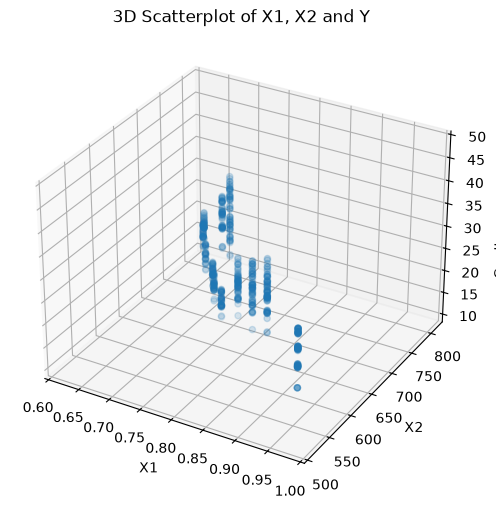

In [80]:
# Part B (1A): 3D scatterplots

# 3D Scatterplot 1: X1, X2 and Y
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(data["X1"], data["X2"], data["Y"], alpha=0.5)

ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("Cooling Load (Y)")
ax.set_title("3D Scatterplot of X1, X2 and Y")

plt.show()

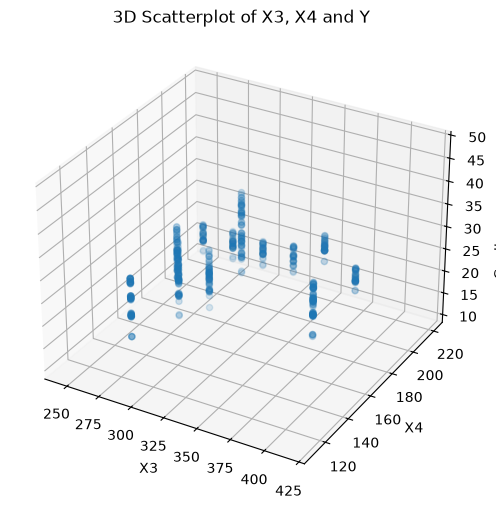

In [81]:
# 3D Scatterplot 2: X3, X4 and Y

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(data["X3"], data["X4"], data["Y"], alpha=0.5)

ax.set_xlabel("X3")
ax.set_ylabel("X4")
ax.set_zlabel("Cooling Load (Y)")
ax.set_title("3D Scatterplot of X3, X4 and Y")

plt.show()

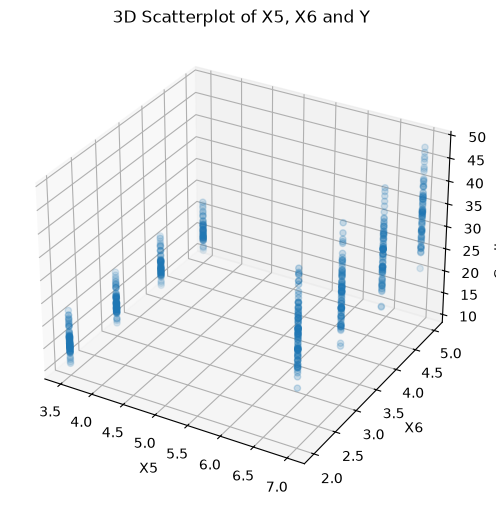

In [82]:
# 3D Scatterplot 3: X5, X6 and Y

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(data["X5"], data["X6"], data["Y"], alpha=0.5)

ax.set_xlabel("X5")
ax.set_ylabel("X6")
ax.set_zlabel("Cooling Load (Y)")
ax.set_title("3D Scatterplot of X5, X6 and Y")

plt.show()

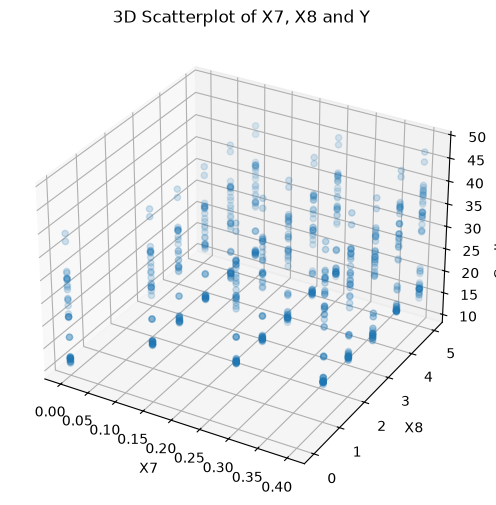

In [83]:
# 3D Scatterplot 4: X7, X8 and Y

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(data["X7"], data["X8"], data["Y"], alpha=0.5)

ax.set_xlabel("X7")
ax.set_ylabel("X8")
ax.set_zlabel("Cooling Load (Y)")
ax.set_title("3D Scatterplot of X7, X8 and Y")

plt.show()

In [84]:
# Part B (1A): Correlation Heatmap
correlation_matrix = data.corr()

correlation_matrix

,X1,X2,X3,X4,X5,X6,X7,X8,Y
X1,1.000000,-0.991956,-0.202571,-0.871413,0.828874,0.000643,-0.002208,-0.001172,0.636107
X2,-0.991956,1.000000,0.195475,0.882667,-0.858808,-0.000760,0.001909,0.000221,-0.674632
X3,-0.202571,0.195475,1.000000,-0.288393,0.279455,0.001671,0.000209,0.003865,0.424202
X4,-0.871413,0.882667,-0.288393,1.000000,-0.972422,-0.001543,0.001764,-0.001636,-0.861971
X5,0.828874,-0.858808,0.279455,-0.972422,1.000000,0.001781,-0.000139,0.003313,0.897329
X6,0.000643,-0.000760,0.001671,-0.001543,0.001781,1.000000,0.004413,0.003788,0.018014
X7,-0.002208,0.001909,0.000209,0.001764,-0.000139,0.004413,1.000000,0.194927,0.203649
X8,-0.001172,0.000221,0.003865,-0.001636,0.003313,0.003788,0.194927,1.000000,0.047965
Y,0.636107,-0.674632,0.424202,-0.861971,0.897329,0.018014,0.203649,0.047965,1.000000


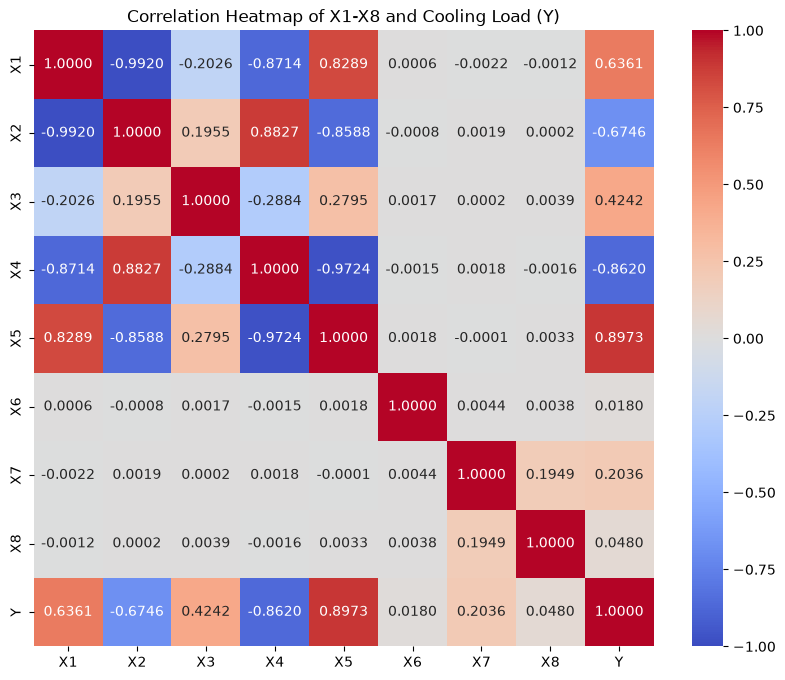

In [85]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".4f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of X1-X8 and Cooling Load (Y)")
plt.show()

In [86]:
# Part B (1B): Split the dataset into an 80% training set and a 20% test set 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (600, 8)
X_test shape: (151, 8)
y_train shape: (600,)
y_test shape: (151,)


Part B - 2. Multiple Linear Regression (MLR- Baseline Model)

In [87]:
# Part B (2A): Fit a Multiple Linear Regression model

mlr_model = LinearRegression()

mlr_model.fit(X_train, y_train)

print("Intercept:", mlr_model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X_train.columns, mlr_model.coef_):
    print(f"{feature}: {coefficient}")

Intercept: 95.79604093619392

Coefficients:
X1: -71.24667385337388
X2: -0.06451273244774854
X3: 0.021425445329556734
X4: -0.04296908889901549
X5: 4.464948978378447
X6: 0.10930818828673626
X7: 14.622791104143458
X8: 0.057986291259714405


In [88]:
# Part B (2B): Evaluate model performance on both training and testing datasets

y_train_pred = mlr_model.predict(X_train)
y_test_pred = mlr_model.predict(X_test)

# Evaluate Training Performance
train_r2 = r2_score(y_train, y_train_pred)

n_train = len(y_train)
p = X_train.shape[1]

train_adjusted_r2 = 1 - (1 - train_r2) * (n_train - 1) / (n_train - p - 1)

train_mae = mean_absolute_error(y_train, y_train_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

# Evaluate Testing Performance
test_r2 = r2_score(y_test, y_test_pred)

n_test = len(y_test)

test_adjusted_r2 = 1 - (1 - test_r2) * (n_test - 1) / (n_test - p - 1)

test_mae = mean_absolute_error(y_test, y_test_pred)

test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("Training Performance")
print("R2:", train_r2)
print("Adjusted R2:", train_adjusted_r2)
print("MAE:", train_mae)
print("RMSE:", train_rmse)

print("\nTesting Performance")
print("R2:", test_r2)
print("Adjusted R2:", test_adjusted_r2)
print("MAE:", test_mae)
print("RMSE:", test_rmse)

Training Performance
R2: 0.8789538623619693
Adjusted R2: 0.8773153359641618
MAE: 2.3584428637790293
RMSE: 3.3142029153916748

Testing Performance
R2: 0.9276362130768029
Adjusted R2: 0.9235593800107073
MAE: 1.7929634410912312
RMSE: 2.5391591011919923


Part B - 3. Polynomial Regression

In [89]:
# Part B (3A): Fit Polynomial Regression models

# Polynomial Regression models of Degree 2
poly2 = PolynomialFeatures(degree=2, include_bias=False)

# Combining the 8 features into pairwise interaction terms
X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)

print("Original features:", X_train.shape[1])
print("Degree 2 features:", X_train_poly2.shape[1])

Original features: 8
Degree 2 features: 44


In [90]:
poly2_model = LinearRegression()
poly2_model.fit(X_train_poly2, y_train)

y_train_poly2_pred = poly2_model.predict(X_train_poly2)
y_test_poly2_pred = poly2_model.predict(X_test_poly2)

In [91]:
# Training Performance
train_poly2_r2 = r2_score(y_train, y_train_poly2_pred)

n_train = len(y_train)
p = X_train_poly2.shape[1]

train_poly2_adjusted_r2 = 1 - (1 - train_poly2_r2) * (n_train - 1) / (n_train - p - 1)

train_poly2_mae = mean_absolute_error(y_train, y_train_poly2_pred)
train_poly2_rmse = np.sqrt(mean_squared_error(y_train, y_train_poly2_pred))


# Testing Performance
test_poly2_r2 = r2_score(y_test, y_test_poly2_pred)

n_test = len(y_test)

test_poly2_adjusted_r2 = 1 - (1 - test_poly2_r2) * (n_test - 1) / (n_test - p - 1)

test_poly2_mae = mean_absolute_error(y_test, y_test_poly2_pred)
test_poly2_rmse = np.sqrt(mean_squared_error(y_test, y_test_poly2_pred))


print("Degree 2 Polynomial Regression")
print("\nTraining Performance:")
print("R2:", train_poly2_r2)
print("Adjusted R2:", train_poly2_adjusted_r2)
print("MAE:", train_poly2_mae)
print("RMSE:", train_poly2_rmse)

print("\nTesting Performance:")
print("R2:", test_poly2_r2)
print("Adjusted R2:", test_poly2_adjusted_r2)
print("MAE:", test_poly2_mae)
print("RMSE:", test_poly2_rmse)

Degree 2 Polynomial Regression

Training Performance:
R2: 0.9227065668878696
Adjusted R2: 0.9165787992177187
MAE: 2.01322962067853
RMSE: 2.648347229332629

Testing Performance:
R2: 0.9272716409392645
Adjusted R2: 0.8970825107631102
MAE: 1.930003076713165
RMSE: 2.545547266390678


In [92]:
# Polynomial Regression models of Degree 3
poly3 = PolynomialFeatures(degree=3, include_bias=False)

X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)

print("Original features:", X_train.shape[1])
print("Degree 3 features:", X_train_poly3.shape[1])

Original features: 8
Degree 3 features: 164


In [93]:
poly3_model = LinearRegression()
poly3_model.fit(X_train_poly3, y_train)

y_train_poly3_pred = poly3_model.predict(X_train_poly3)
y_test_poly3_pred = poly3_model.predict(X_test_poly3)

In [94]:
# Training Performance
train_poly3_r2 = r2_score(y_train, y_train_poly3_pred)

n_train = len(y_train)
p = X_train_poly3.shape[1]

train_poly3_adjusted_r2 = 1 - (1 - train_poly3_r2) * (n_train - 1) / (n_train - p - 1)

train_poly3_mae = mean_absolute_error(y_train, y_train_poly3_pred)
train_poly3_rmse = np.sqrt(mean_squared_error(y_train, y_train_poly3_pred))


# Testing Performance
test_poly3_r2 = r2_score(y_test, y_test_poly3_pred)

n_test = len(y_test)

if n_test > p + 1:
    test_poly3_adjusted_r2 = 1 - (1 - test_poly3_r2) * (n_test - 1) / (n_test - p - 1)
else:
    test_poly3_adjusted_r2 = None

test_poly3_mae = mean_absolute_error(y_test, y_test_poly3_pred)
test_poly3_rmse = np.sqrt(mean_squared_error(y_test, y_test_poly3_pred))


print("Degree 3 Polynomial Regression")
print("\nTraining Performance:")
print("R2:", train_poly3_r2)
print("Adjusted R2:", train_poly3_adjusted_r2)
print("MAE:", train_poly3_mae)
print("RMSE:", train_poly3_rmse)

print("\nTesting Performance:")
print("R2:", test_poly3_r2)
print("Adjusted R2:", test_poly3_adjusted_r2)
print("MAE:", test_poly3_mae)
print("RMSE:", test_poly3_rmse)

Degree 3 Polynomial Regression

Training Performance:
R2: 0.9203191248434638
Adjusted R2: 0.8902785190373214
MAE: 2.035888098307361
RMSE: 2.688937293358459

Testing Performance:
R2: 0.9256825616545504
Adjusted R2: None
MAE: 1.93542084272396
RMSE: 2.573206482731361


Part B - 4. Multiple Linear Regression with Principal Component Analysis (MLR + PCA Model)

In [95]:
# Part B (4A): Standardise the numerical predictors using Z-score feature scaling

# Standardisation
scaler_pca = StandardScaler()

X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)

# Check the results
print("Training data mean:")
print(X_train_scaled.mean(axis=0))

print("\nTraining data standard deviation:")
print(X_train_scaled.std(axis=0))

Training data mean:
[-9.41469125e-16  1.22864681e-16  6.35787719e-16 -2.01320442e-16
 -7.25345709e-17 -2.59052039e-17 -2.42768768e-16 -4.73695157e-17]

Training data standard deviation:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [96]:
# Part B (4B): Perform Principal Component Analysis (PCA)

pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Explained variance ratio
explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:")
print(explained_variance)

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

print("\nCumulative Explained Variance:")
print(cumulative_variance)

Explained Variance Ratio:
[0.46372048 0.15456137 0.14692621 0.12508593 0.10235542 0.00682802
 0.00052258 0.        ]

Cumulative Explained Variance:
[0.46372048 0.61828184 0.76520805 0.89029398 0.9926494  0.99947742
 1.         1.        ]


The PCA results show that PC1 explains 46.37% of the total variance, followed by PC2, which explains 15.46%. The first five principal components collectively explain approximately 99.26% of the total variance. Therefore, five principal components can be selected to retain most of the information from the original eight features while reducing the number of predictors from eight to five.

In [97]:
# Part B (4C): Get eigenvector loadings

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i}" for i in range(1, 9)],
    index=X_train.columns
)

print("Eigenvector Loadings:")
print(loadings[["PC1", "PC2"]])

Eigenvector Loadings:
         PC1       PC2
X1 -0.496841 -0.234113
X2  0.502494  0.222354
X3 -0.021491  0.893392
X4  0.504842 -0.203124
X5 -0.494563  0.216306
X6  0.005058 -0.007459
X7  0.022424 -0.027307
X8  0.014153  0.093547


In [98]:
# Part B (4D): Train an MLR + PCA model

# Select the first 5 principal components
X_train_pca_selected = X_train_pca[:, :5]
X_test_pca_selected = X_test_pca[:, :5]

print("Training PCA shape:", X_train_pca_selected.shape)
print("Testing PCA shape:", X_test_pca_selected.shape)

Training PCA shape: (600, 5)
Testing PCA shape: (151, 5)


In [99]:
# Create and train MLR + PCA model
pca_mlr_model = LinearRegression()
pca_mlr_model.fit(X_train_pca_selected, y_train)

# Make predictions
y_train_pca_pred = pca_mlr_model.predict(X_train_pca_selected)
y_test_pca_pred = pca_mlr_model.predict(X_test_pca_selected)

In [100]:
# Part B (4E): Compare the test set performance of the MLR + PCA model against the baseline MLR model

# Calculate Training Metrics
train_r2_pca = r2_score(y_train, y_train_pca_pred)
train_adj_r2_pca = 1 - (1 - train_r2_pca) * (len(y_train) - 1) / (len(y_train) - 5 - 1)
train_mae_pca = mean_absolute_error(y_train, y_train_pca_pred)
train_rmse_pca = np.sqrt(mean_squared_error(y_train, y_train_pca_pred))

# Calculate Testing Metrics
test_r2_pca = r2_score(y_test, y_test_pca_pred)
test_adj_r2_pca = 1 - (1 - test_r2_pca) * (len(y_test) - 1) / (len(y_test) - 5 - 1)
test_mae_pca = mean_absolute_error(y_test, y_test_pca_pred)
test_rmse_pca = np.sqrt(mean_squared_error(y_test, y_test_pca_pred))

print("MLR + PCA Training Performance")
print("R-squared:", train_r2_pca)
print("Adjusted R-squared:", train_adj_r2_pca)
print("MAE:", train_mae_pca)
print("RMSE:", train_rmse_pca)

print("\nMLR + PCA Testing Performance")
print("R-squared:", test_r2_pca)
print("Adjusted R-squared:", test_adj_r2_pca)
print("MAE:", test_mae_pca)
print("RMSE:", test_rmse_pca)

MLR + PCA Training Performance
R-squared: 0.8290529247371254
Adjusted R-squared: 0.8276139762921517
MAE: 2.8285436031311892
RMSE: 3.938532778174664

MLR + PCA Testing Performance
R-squared: 0.8926701433396148
Adjusted R-squared: 0.8889691137996015
MAE: 2.2305330830067835
RMSE: 3.092356431186889


In [101]:
# Compare Baseline MLR and MLR + PCA Testing Performance

comparison_table = pd.DataFrame({
    "Model": [
        "Baseline MLR",
        "MLR + PCA"
    ],
    "Testing R2": [
        test_r2,
        test_r2_pca
    ],
    "Testing Adjusted R2": [
        test_adjusted_r2,
        test_adj_r2_pca
    ],
    "Testing MAE": [
        test_mae,
        test_mae_pca
    ],
    "Testing RMSE": [
        test_rmse,
        test_rmse_pca
    ]
})

comparison_table.round(4)

,Model,Testing R2,Testing Adjusted R2,Testing MAE,Testing RMSE
0,Baseline MLR,0.9276,0.9236,1.7930,2.5392
1,MLR + PCA,0.8927,0.8890,2.2305,3.0924


In [102]:
# Part B (4G): Compare the performance for all models

comparison_table = pd.DataFrame({
    "Model": [
        "Baseline MLR",
        "Polynomial Degree 2",
        "Polynomial Degree 3",
        "MLR + PCA"
    ],
    "Testing R2": [
        test_r2,
        test_poly2_r2,
        test_poly3_r2,
        test_r2_pca
    ],
    "Testing Adjusted R2": [
        test_adjusted_r2,
        test_poly2_adjusted_r2,
        None,
        test_adj_r2_pca
    ],
    "Testing MAE": [
        test_mae,
        test_poly2_mae,
        test_poly3_mae,
        test_mae_pca
    ],
    "Testing RMSE": [
        test_rmse,
        test_poly2_rmse,
        test_poly3_rmse,
        test_rmse_pca
    ]
})

comparison_table.round(4)

,Model,Testing R2,Testing Adjusted R2,Testing MAE,Testing RMSE
0,Baseline MLR,0.9276,0.9236,1.7930,2.5392
1,Polynomial Degree 2,0.9273,0.8971,1.9300,2.5455
2,Polynomial Degree 3,0.9257,NaN,1.9354,2.5732
3,MLR + PCA,0.8927,0.8890,2.2305,3.0924


In [103]:
# Diagnostic Check: Standardized Baseline MLR
scaler_diag = StandardScaler()
X_train_scaled_diag = scaler_diag.fit_transform(X_train)

print("Baseline MLR Rank:",
      np.linalg.matrix_rank(X_train_scaled_diag),
      "/", X_train_scaled_diag.shape[1])

print("Baseline MLR Condition Number:",
      np.linalg.cond(X_train_scaled_diag))

Baseline MLR Rank: 7 / 8
Baseline MLR Condition Number: 1.1734829337481374e+16


**Additional Evaluation Using Lasso-Selected Features**

In [104]:
# Part B: Lasso-selected MLR

# Step 1: Standardise Training and Testing Data
scaler_lasso = StandardScaler()

X_train_scaled = scaler_lasso.fit_transform(X_train)
X_test_scaled = scaler_lasso.transform(X_test)

# Step 2: Check the Shape
print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

Training Data Shape: (600, 8)
Testing Data Shape: (151, 8)


In [105]:
# Step 3: Perform Lasso Feature Selection

lasso_cv = LassoCV(
    cv=5,
    max_iter=100000
)

# Train LassoCV using Training Data only
lasso_cv.fit(X_train_scaled, y_train)

# Display the Best Alpha
print("Best Alpha:", lasso_cv.alpha_)

# Step 4: Identify Selected Features

lasso_coefficients = pd.Series(
    lasso_cv.coef_,
    index=X_train.columns
)

selected_features = lasso_coefficients[
    np.abs(lasso_cv.coef_) > 1e-8
].index.tolist()

print("\nLasso Coefficients:")
print(lasso_coefficients)

print("\nSelected Features:")
print(selected_features)

print("\nNumber of Selected Features:", len(selected_features))

Best Alpha: 0.008481605424207079

Lasso Coefficients:
X1   -5.884754
X2   -2.057197
X3   -0.000000
X4   -3.300506
X5    8.438622
X6    0.117824
X7    1.943957
X8    0.078322
dtype: float64

Selected Features:
['X1', 'X2', 'X4', 'X5', 'X6', 'X7', 'X8']

Number of Selected Features: 7


In [106]:
# Step 5: Create Post-Lasso Multiple Linear Regression Model

# Select the Lasso-selected Features
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

# Create and Train the MLR Model
model_lasso_mlr = LinearRegression()

model_lasso_mlr.fit(X_train_selected, y_train)

# Predict Training and Testing Data
y_train_pred_lasso = model_lasso_mlr.predict(X_train_selected)
y_test_pred_lasso = model_lasso_mlr.predict(X_test_selected)

In [107]:
# Step 6: Evaluate Post-Lasso MLR Performance

# Define Evaluation Function
def evaluate_model(y_true, y_pred, n_features):
    n = len(y_true)

    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    return float(r2), float(adj_r2), float(mae), float(rmse)


# Number of Selected Features
n_features = len(selected_features)


# Training Performance
train_lasso_mlr_results = evaluate_model(
    y_train, y_train_pred_lasso, n_features
)

# Testing Performance
test_lasso_mlr_results = evaluate_model(
    y_test, y_test_pred_lasso, n_features
)


# Display Results
print("========== LASSO-SELECTED MLR PERFORMANCE ==========")

print("\nTraining Performance:")
print("R-squared:", train_lasso_mlr_results[0])
print("Adjusted R-squared:", train_lasso_mlr_results[1])
print("MAE:", train_lasso_mlr_results[2])
print("RMSE:", train_lasso_mlr_results[3])

print("\nTesting Performance:")
print("R-squared:", test_lasso_mlr_results[0])
print("Adjusted R-squared:", test_lasso_mlr_results[1])
print("MAE:", test_lasso_mlr_results[2])
print("RMSE:", test_lasso_mlr_results[3])

========== LASSO-SELECTED MLR PERFORMANCE ==========

Training Performance:
R-squared: 0.8789538623619689
Adjusted R-squared: 0.87752257357233
MAE: 2.358442863779029
RMSE: 3.3142029153916783

Testing Performance:
R-squared: 0.9276362130768028
Adjusted R-squared: 0.924093929800842
MAE: 1.792963441091227
RMSE: 2.539159101191993


In [108]:
# Additional Experiment: Lasso-selected Polynomial Regression

# Step 1: Standardise Selected Features

scaler_selected = StandardScaler()

X_train_selected_scaled = scaler_selected.fit_transform(X_train_selected)
X_test_selected_scaled = scaler_selected.transform(X_test_selected)


# Step 2: Generate Degree 2 Polynomial Features

poly_2_lasso = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly2_lasso = poly_2_lasso.fit_transform(X_train_selected_scaled)
X_test_poly2_lasso = poly_2_lasso.transform(X_test_selected_scaled)


# Step 3: Generate Degree 3 Polynomial Features

poly_3_lasso = PolynomialFeatures(degree=3, include_bias=False)

X_train_poly3_lasso = poly_3_lasso.fit_transform(X_train_selected_scaled)
X_test_poly3_lasso = poly_3_lasso.transform(X_test_selected_scaled)


# Step 4: Standardise Polynomial Features

# Degree 2
scaler_poly2 = StandardScaler()

X_train_poly2_scaled = scaler_poly2.fit_transform(X_train_poly2_lasso)
X_test_poly2_scaled = scaler_poly2.transform(X_test_poly2_lasso)


# Degree 3
scaler_poly3 = StandardScaler()

X_train_poly3_scaled = scaler_poly3.fit_transform(X_train_poly3_lasso)
X_test_poly3_scaled = scaler_poly3.transform(X_test_poly3_lasso)


# Step 5: Check Shape

print("Degree 2 Training Shape:", X_train_poly2_scaled.shape)
print("Degree 2 Testing Shape:", X_test_poly2_scaled.shape)

print("\nDegree 3 Training Shape:", X_train_poly3_scaled.shape)
print("Degree 3 Testing Shape:", X_test_poly3_scaled.shape)

Degree 2 Training Shape: (600, 35)
Degree 2 Testing Shape: (151, 35)

Degree 3 Training Shape: (600, 119)
Degree 3 Testing Shape: (151, 119)


In [109]:
# Diagnostic Check: Condition Number

print("Degree 2 Condition Number:",
      np.linalg.cond(X_train_poly2_scaled))

print("Degree 3 Condition Number:",
      np.linalg.cond(X_train_poly3_scaled))

Degree 2 Condition Number: 2.06535837076518e+16
Degree 3 Condition Number: 3.387569691846273e+19


High Condition Number

Both models have extremely high condition numbers, indicating severe numerical instability. This suggests that the polynomial features are highly correlated or nearly linearly dependent, making the regression coefficients sensitive to small changes in the data.

In [110]:
# Diagnostic Check: Matrix Rank

print("Degree 2 Rank:",
      np.linalg.matrix_rank(X_train_poly2_scaled),
      "/", X_train_poly2_scaled.shape[1])

print("Degree 3 Rank:",
      np.linalg.matrix_rank(X_train_poly3_scaled),
      "/", X_train_poly3_scaled.shape[1])

Degree 2 Rank: 32 / 35
Degree 3 Rank: 87 / 119


Rank Deficiency

Degree 2 has 35 polynomial features but a matrix rank of only 32. Degree 3 has 119 polynomial features but a matrix rank of only 87. This indicates that some polynomial features have linear dependencies, resulting in redundant information.

Both Lasso-selected Polynomial Regression models exhibit numerical instability due to rank deficiency and extremely high condition numbers.

These results indicate strong linear dependencies among the polynomial features, which may cause unstable regression coefficients and reduce model reliability. Therefore, the coefficients and predictions should be interpreted with caution. 

In [111]:
# Step 2: Train Polynomial Regression Models

# Degree 2 Model
model_poly2_lasso = LinearRegression()
model_poly2_lasso.fit(X_train_poly2_scaled, y_train)

# Degree 3 Model
model_poly3_lasso = LinearRegression()
model_poly3_lasso.fit(X_train_poly3_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](119,)","[-32.09,-15.49,-21.47,..., 0.12, -0.06, -0.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,24.75
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,119
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(87)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](119,)","[134.47, 93.58, 83.31,..., 0. , 0. , 0. ]"


In [112]:
# Step 3: Predict Training and Testing Data

# Degree 2 Predictions
y_train_pred_poly2_lasso = model_poly2_lasso.predict(X_train_poly2_scaled)
y_test_pred_poly2_lasso = model_poly2_lasso.predict(X_test_poly2_scaled)

# Degree 3 Predictions
y_train_pred_poly3_lasso = model_poly3_lasso.predict(X_train_poly3_scaled)
y_test_pred_poly3_lasso = model_poly3_lasso.predict(X_test_poly3_scaled)


# Step 4: Evaluate Polynomial Regression Models

# Degree 2 Performance
train_lasso_poly2_results = evaluate_model(
    y_train, y_train_pred_poly2_lasso, model_poly2_lasso.rank_
)

test_lasso_poly2_results = evaluate_model(
    y_test, y_test_pred_poly2_lasso, model_poly2_lasso.rank_
)


# Degree 3 Performance
train_lasso_poly3_results = evaluate_model(
    y_train, y_train_pred_poly3_lasso, model_poly3_lasso.rank_
)

test_lasso_poly3_results = evaluate_model(
    y_test, y_test_pred_poly3_lasso, model_poly3_lasso.rank_
)


# Display Results
print("========== LASSO-SELECTED POLYNOMIAL REGRESSION ==========")

for degree, train_results, test_results in [
    ("Degree 2", train_lasso_poly2_results, test_lasso_poly2_results),
    ("Degree 3", train_lasso_poly3_results, test_lasso_poly3_results)
]:
    print(f"\n{degree}")

    print("\nTraining Performance:")
    print("R-squared:", train_results[0])
    print("Adjusted R-squared:", train_results[1])
    print("MAE:", train_results[2])
    print("RMSE:", train_results[3])

    print("\nTesting Performance:")
    print("R-squared:", test_results[0])
    print("Adjusted R-squared:", test_results[1])
    print("MAE:", test_results[2])
    print("RMSE:", test_results[3])

========== LASSO-SELECTED POLYNOMIAL REGRESSION ==========

Degree 2

Training Performance:
R-squared: 0.9708060647473866
Adjusted R-squared: 0.9691584352445937
MAE: 1.1021705234749763
RMSE: 1.62760849172415

Testing Performance:
R-squared: 0.9751502118481506
Adjusted R-squared: 0.9684112862476492
MAE: 0.9824775434453245
RMSE: 1.4879578071349597

Degree 3

Training Performance:
R-squared: 0.9770219017948071
Adjusted R-squared: 0.9731174202638465
MAE: 1.0488752725865194
RMSE: 1.4439783021907275

Testing Performance:
R-squared: 0.9748990463592893
Adjusted R-squared: 0.9402358246649745
MAE: 1.1119784938860995
RMSE: 1.49545855626275


Due to their numerical instability, both Lasso-selected Polynomial Regression models will not be considered as preferred models.

In [113]:
# Additional Experiment: Lasso-selected MLR + PCA

# Step 1: Reuse Standardised Selected Features
X_train_scaled_pca_lasso = X_train_selected_scaled
X_test_scaled_pca_lasso = X_test_selected_scaled


# Step 2: Check Shape
print("Training Data Shape:", X_train_scaled_pca_lasso.shape)
print("Testing Data Shape:", X_test_scaled_pca_lasso.shape)

Training Data Shape: (600, 7)
Testing Data Shape: (151, 7)


In [114]:
# Step 3: Perform Principal Component Analysis

pca_lasso = PCA()

# Fit PCA using Training Data
X_train_pca_lasso = pca_lasso.fit_transform(
    X_train_scaled_pca_lasso
)

# Transform Testing Data
X_test_pca_lasso = pca_lasso.transform(
    X_test_scaled_pca_lasso
)


# Step 4: Display Explained Variance Ratio
print("Explained Variance Ratio:")
print(pca_lasso.explained_variance_ratio_)


# Step 5: Display Cumulative Explained Variance
print("\nCumulative Explained Variance:")
print(np.cumsum(pca_lasso.explained_variance_ratio_))

Explained Variance Ratio:
[0.52979179 0.16793415 0.14295551 0.11746601 0.03726948 0.00402695
 0.00055612]

Cumulative Explained Variance:
[0.52979179 0.69772593 0.84068144 0.95814745 0.99541693 0.99944388
 1.        ]


In [115]:
# Step 6: Examine Eigenvector Loadings

loadings_lasso = pd.DataFrame(
    pca_lasso.components_.T,
    index=selected_features,
    columns=[f"PC{i+1}" for i in range(7)]
)

print("\nEigenvector Loadings for PC1 and PC2:")
print(loadings_lasso[["PC1", "PC2"]])


Eigenvector Loadings for PC1 and PC2:
         PC1       PC2
X1 -0.498470  0.012672
X2  0.504072 -0.013008
X4  0.503480 -0.014077
X5 -0.493173  0.012435
X6  0.005030  0.051875
X7  0.022264  0.703515
X8  0.014358  0.708303


In [116]:
# Step 7: Compare 4 PCs and 5 PCs

pca_comparison_results = []

for n_components in [4, 5]:

    X_train_pca_selected = X_train_pca_lasso[:, :n_components]
    X_test_pca_selected = X_test_pca_lasso[:, :n_components]

    # Train Model
    model = LinearRegression()
    model.fit(X_train_pca_selected, y_train)

    # Predictions
    y_train_pred = model.predict(X_train_pca_selected)
    y_test_pred = model.predict(X_test_pca_selected)

    # Evaluate Performance
    train_results = evaluate_model(
        y_train, y_train_pred, n_components
    )

    test_results = evaluate_model(
        y_test, y_test_pred, n_components
    )

    pca_comparison_results.append({
        "Number of PCs": n_components,
        "Training R2": train_results[0],
        "Testing R2": test_results[0],
        "Testing Adjusted R2": test_results[1],
        "Testing MAE": test_results[2],
        "Testing RMSE": test_results[3]
    })


# Display Comparison
pca_comparison_table = pd.DataFrame(pca_comparison_results)

print("========== PCA COMPONENT COMPARISON ==========")
print(pca_comparison_table.round(4).to_string(index=False))

========== PCA COMPONENT COMPARISON ==========
 Number of PCs  Training R2  Testing R2  Testing Adjusted R2  Testing MAE  Testing RMSE
             4       0.6599      0.7458               0.7389       3.7312        4.7587
             5       0.8709      0.9210               0.9182       2.0093        2.6538


In [117]:
# Step 8: Select the First Five Principal Components

n_components = 5

X_train_pca_selected = X_train_pca_lasso[:, :n_components]
X_test_pca_selected = X_test_pca_lasso[:, :n_components]

# Check Shape
print("Training Data Shape:", X_train_pca_selected.shape)
print("Testing Data Shape:", X_test_pca_selected.shape)

Training Data Shape: (600, 5)
Testing Data Shape: (151, 5)


In [118]:
# Step 9: Train Lasso-selected MLR + PCA Model

model_pca_lasso = LinearRegression()

model_pca_lasso.fit(X_train_pca_selected, y_train)


# Step 10: Predict Training and Testing Data

y_train_pred_pca_lasso = model_pca_lasso.predict(
    X_train_pca_selected
)

y_test_pred_pca_lasso = model_pca_lasso.predict(
    X_test_pca_selected
)


# Step 11: Evaluate Lasso-selected MLR + PCA

# Training Performance
train_pca_lasso_results = evaluate_model(
    y_train, y_train_pred_pca_lasso, n_components
)

# Testing Performance
test_pca_lasso_results = evaluate_model(
    y_test, y_test_pred_pca_lasso, n_components
)


# Display Results
print("========== LASSO-SELECTED MLR + PCA ==========")

print("\nTraining Performance:")
print("R-squared:", train_pca_lasso_results[0])
print("Adjusted R-squared:", train_pca_lasso_results[1])
print("MAE:", train_pca_lasso_results[2])
print("RMSE:", train_pca_lasso_results[3])

print("\nTesting Performance:")
print("R-squared:", test_pca_lasso_results[0])
print("Adjusted R-squared:", test_pca_lasso_results[1])
print("MAE:", test_pca_lasso_results[2])
print("RMSE:", test_pca_lasso_results[3])

========== LASSO-SELECTED MLR + PCA ==========

Training Performance:
R-squared: 0.8709366595596594
Adjusted R-squared: 0.8698502678051111
MAE: 2.521127026448847
RMSE: 3.42219756140287

Testing Performance:
R-squared: 0.9209534986655782
Adjusted R-squared: 0.9182277572402533
MAE: 2.0093016792659295
RMSE: 2.6538147117650377


In [119]:
# Part B (4G): Compare the Performance of All Models
comparison_table = pd.DataFrame({
    "Model": [
        "Baseline MLR",
        "Polynomial Degree 2",
        "Polynomial Degree 3",
        "MLR + PCA",
        "Post-Lasso MLR",
        "Lasso-selected Polynomial Degree 2",
        "Lasso-selected Polynomial Degree 3",
        "Lasso-selected MLR + PCA"
    ],
    "Testing R2": [
        test_r2,
        test_poly2_r2,
        test_poly3_r2,
        test_r2_pca,
        test_lasso_mlr_results[0],
        test_lasso_poly2_results[0],
        test_lasso_poly3_results[0],
        test_pca_lasso_results[0]
    ],
    "Testing Adjusted R2": [
        test_adjusted_r2,
        test_poly2_adjusted_r2,
        None,
        test_adj_r2_pca,
        test_lasso_mlr_results[1],
        test_lasso_poly2_results[1],
        test_lasso_poly3_results[1],
        test_pca_lasso_results[1]
    ],
    "Testing MAE": [
        test_mae,
        test_poly2_mae,
        test_poly3_mae,
        test_mae_pca,
        test_lasso_mlr_results[2],
        test_lasso_poly2_results[2],
        test_lasso_poly3_results[2],
        test_pca_lasso_results[2]
    ],
    "Testing RMSE": [
        test_rmse,
        test_poly2_rmse,
        test_poly3_rmse,
        test_rmse_pca,
        test_lasso_mlr_results[3],
        test_lasso_poly2_results[3],
        test_lasso_poly3_results[3],
        test_pca_lasso_results[3]
    ]
})

comparison_table.round(4)

,Model,Testing R2,Testing Adjusted R2,Testing MAE,Testing RMSE
0,Baseline MLR,0.9276,0.9236,1.7930,2.5392
1,Polynomial Degree 2,0.9273,0.8971,1.9300,2.5455
2,Polynomial Degree 3,0.9257,NaN,1.9354,2.5732
3,MLR + PCA,0.8927,0.8890,2.2305,3.0924
4,Post-Lasso MLR,0.9276,0.9241,1.7930,2.5392
5,Lasso-selected Polynomial Degree 2,0.9752,0.9684,0.9825,1.4880
6,Lasso-selected Polynomial Degree 3,0.9749,0.9402,1.1120,1.4955
7,Lasso-selected MLR + PCA,0.9210,0.9182,2.0093,2.6538


#### -------------------------------------<br>PART C: MODEL DEPLOYMENT<br>-------------------------------------

Part C - 1. Model Persistence & Serialisation

In [120]:
# Part C: MODEL PERSISTENCE & SERIALISATION

# Step 1: Export Lasso-selected MLR Model

# Save Model and Preprocessing Objects
model_bundle = {
    "selected_features": selected_features,
    "model": model_lasso_mlr
}

# Save Model as Pickle File
model_path = Path("lasso_selected_mlr_cooling_load_model.pkl")

with open(model_path, "wb") as file:
    pickle.dump(model_bundle, file)

print("Lasso-selected MLR Model successfully saved!")
print("File Location:", model_path.resolve())

Lasso-selected MLR Model successfully saved!
File Location: C:\Users\KKM\Documents\DEVELOPMENT\Predictive_Analytics\lasso_selected_mlr_cooling_load_model.pkl


In [121]:
# Step 2: Load Lasso-selected MLR Model
with open("lasso_selected_mlr_cooling_load_model.pkl", "rb") as file:
    model_bundle = pickle.load(file)

print("Lasso-selected MLR Model successfully loaded!")

# Step 3: Verify Loaded Model
print("Selected Features:", model_bundle["selected_features"])
print("Model Type:", type(model_bundle["model"]).__name__)

Lasso-selected MLR Model successfully loaded!
Selected Features: ['X1', 'X2', 'X4', 'X5', 'X6', 'X7', 'X8']
Model Type: LinearRegression


In [122]:
# Step 3: Test Model Prediction

# Prepare Sample Input
input_values = X_test.iloc[0].tolist()
input_df = pd.DataFrame([input_values], columns=[f"X{i}" for i in range(1, 9)])

# Select Lasso-selected Features
X_input_selected = input_df[model_bundle["selected_features"]]

# Predict Cooling Load
prediction = model_bundle["model"].predict(X_input_selected)[0]

print("Predicted Cooling Load:", prediction)
print("Actual Cooling Load:", y_test.iloc[0])

Predicted Cooling Load: 31.991928059307703
Actual Cooling Load: 28.02


In [123]:
# Calculate Prediction Error
error = y_test.iloc[0] - prediction
absolute_error = abs(error)

print("Prediction Error:", error)
print("Absolute Error:", absolute_error)

Prediction Error: -3.9719280593077038
Absolute Error: 3.9719280593077038


In [124]:
# Prepare Sample Inputs
input_df = X_test.iloc[:5].copy()

# Select Lasso-selected Features
X_input_selected = input_df[model_bundle["selected_features"]]

# Predict Cooling Load
predictions = model_bundle["model"].predict(X_input_selected)

# Compare Predictions with Actual Values
results = pd.DataFrame({
    "Actual Cooling Load": y_test.iloc[:5].values,
    "Predicted Cooling Load": predictions
})

results["Absolute Error"] = abs(
    results["Actual Cooling Load"] - results["Predicted Cooling Load"]
)

print(results)

   Actual Cooling Load  Predicted Cooling Load  Absolute Error
0                28.02               31.991928        3.971928
1                15.85               15.770291        0.079709
2                14.24               15.615840        1.375840
3                34.25               35.858851        1.608851
4                37.58               37.929632        0.349632
